# 04. How much data, which mix, and how to look like competition posts

**Questions:** How many rows are worth the time? Should training be mostly Ukrainian? Do newline tokens, synthetic long posts and extra address rows help?

**Already known from the EDA:** recall is 81–87% for names seen in training and about 24–35% for unseen names. The pilots used about 25% of the rows in the training folds. Ukrainian labels alone raised Ukrainian F1 by 0.05 but collapsed russian F1, though that test also doubled Ukrainian rows.

**Reading the columns:**

- `mix_f1`: held-out source sentences, weighted 90/10.
- `posts_f1`: synthetic multi-line posts built from the held-out fold. It stresses long inputs, but it isn't competition data.
- `labeling_f1`: the 26 labeled posts, 26 is too few, so never tune on them.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "eda").exists():
    ROOT = ROOT.parent
sys.path[:0] = [str(ROOT), str(ROOT / "model")]

import matplotlib.pyplot as plt
from IPython.display import display

from nerkit import plots
from nerkit.experiment import read_results, run_grid, summarize

NOTEBOOK = "04_data_strategy"

## 1. Learning curve
If the curve is still rising at the largest size, more data is the cheapest gain. Sizes above about 20k per language use the extra rows outside CV, and they stay leak-free.

rows_5000: F1 mix 0.826, uk 0.816, ru 0.897, 41 s on cpu


rows_10000: F1 mix 0.856, uk 0.846, ru 0.924, 107 s on cpu


rows_20000: F1 mix 0.872, uk 0.863, ru 0.936, 205 s on cpu


rows_50000: F1 mix 0.871, uk 0.859, ru 0.946, 453 s on cpu


rows_100000: F1 mix 0.885, uk 0.875, ru 0.954, 802 s on cpu


,runs,mix_f1,spread,uk_f1,ru_f1,precision,recall,uk_unseen_recall,posts_f1,labeling_f1,minutes
name,,,,,,,,,,,
rows_5000,1,0.826,0.0,0.816,0.897,0.839,0.814,0.668,0.814,0.640,0.682
rows_10000,1,0.856,0.0,0.846,0.924,0.848,0.864,0.669,0.832,0.617,1.782
rows_20000,1,0.872,0.0,0.863,0.936,0.858,0.887,0.703,0.868,0.675,3.424
rows_50000,1,0.871,0.0,0.859,0.946,0.915,0.831,0.555,0.865,0.704,7.551
rows_100000,1,0.885,0.0,0.875,0.954,0.912,0.860,0.614,0.875,0.667,13.364


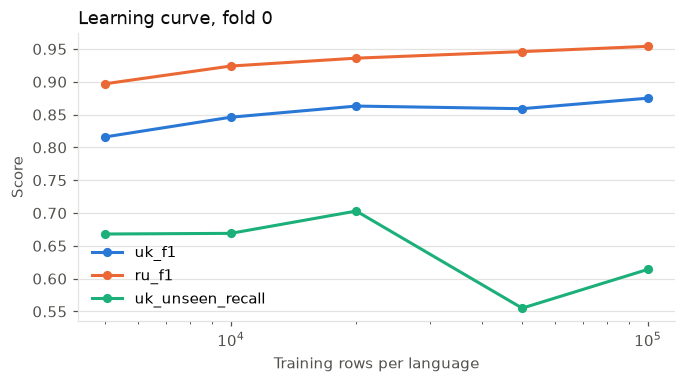

In [2]:
SIZES = [5_000, 10_000, 20_000, 50_000, 100_000]
run_grid(NOTEBOOK, {f"rows_{n}": dict(uk_rows=n, ru_rows=n) for n in SIZES})
table = summarize(NOTEBOOK).loc[[f"rows_{n}" for n in SIZES if f"rows_{n}" in summarize(NOTEBOOK).index]]
display(table)
figure, axis = plt.subplots(figsize=(7, 3.4))
for color, column in zip(plots.SERIES, ("uk_f1", "ru_f1", "uk_unseen_recall")):
    axis.plot(SIZES[:len(table)], table[column], color=color, linewidth=2, marker="o", markersize=5, label=column)
axis.set(xscale="log", xlabel="Training rows per language", ylabel="Score", title="Learning curve, fold 0")
axis.grid(axis="x", visible=False)
axis.legend();

## 2. Language mix
The total stays fixed at 40k rows. The test set is about 90% Ukrainian, but russian rows still teach general patterns, and about 10% of test posts need them.

In [3]:
GROUP = {"uk_50_ru_50": dict(uk_rows=20_000, ru_rows=20_000), "uk_70_ru_30": dict(uk_rows=28_000, ru_rows=12_000),
         "uk_90_ru_10": dict(uk_rows=36_000, ru_rows=4_000)}
run_grid(NOTEBOOK, GROUP)
display(summarize(NOTEBOOK).loc[list(GROUP)])

uk_50_ru_50: F1 mix 0.872, uk 0.863, ru 0.936, 206 s on cpu


uk_70_ru_30: F1 mix 0.873, uk 0.866, ru 0.926, 200 s on cpu


uk_90_ru_10: F1 mix 0.871, uk 0.867, ru 0.895, 137 s on cpu


,runs,mix_f1,spread,uk_f1,ru_f1,precision,recall,uk_unseen_recall,posts_f1,labeling_f1,minutes
name,,,,,,,,,,,
uk_50_ru_50,1,0.872,0.0,0.863,0.936,0.858,0.887,0.703,0.868,0.675,3.428
uk_70_ru_30,1,0.873,0.0,0.866,0.926,0.890,0.858,0.628,0.872,0.603,3.341
uk_90_ru_10,1,0.871,0.0,0.867,0.895,0.882,0.860,0.677,0.867,0.582,2.289


## 3. Looking like competition posts
Newline tokens let the model see lists and footers. Synthetic posts join sentences and add unlabeled footers. Address boost repeats rows with street or landmark mentions; it matters if notebook 00 found a label gap.

Watch `posts_f1` and `labeling_f1` for improvement, and `mix_f1` for damage.

reference: F1 mix 0.856, uk 0.846, ru 0.924, 108 s on cpu


structure_tokens: F1 mix 0.852, uk 0.841, ru 0.925, 97 s on cpu


posts_50: F1 mix 0.854, uk 0.845, ru 0.920, 157 s on cpu


posts_100: F1 mix 0.854, uk 0.844, ru 0.918, 109 s on cpu


address_boost_3: F1 mix 0.857, uk 0.847, ru 0.921, 79 s on cpu


posts_50_address_boost_3: F1 mix 0.839, uk 0.827, ru 0.922, 177 s on cpu


,mix_f1,vs_baseline,uk_f1,ru_f1,posts_f1,labeling_f1,precision,recall,minutes
name,,,,,,,,,
reference,0.856,0.000,0.846,0.924,0.832,0.617,0.848,0.864,1.793
structure_tokens,0.852,-0.004,0.841,0.925,0.849,0.634,0.859,0.845,1.617
posts_50,0.854,-0.002,0.845,0.920,0.845,0.571,0.870,0.839,2.611
posts_100,0.854,-0.002,0.844,0.918,0.841,0.571,0.850,0.857,1.815
address_boost_3,0.857,0.001,0.847,0.921,0.837,0.675,0.867,0.847,1.310
posts_50_address_boost_3,0.839,-0.017,0.827,0.922,0.833,0.630,0.873,0.808,2.948


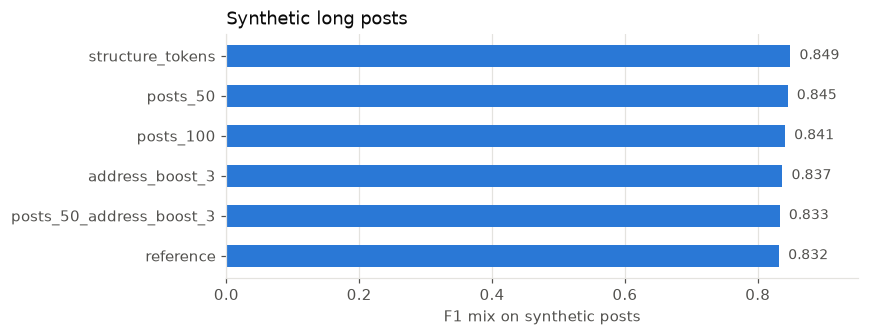

In [4]:
GROUP = {
    "reference": dict(),
    "structure_tokens": dict(structure_tokens=True),
    "posts_50": dict(structure_tokens=True, pseudo_post_fraction=0.5),
    "posts_100": dict(structure_tokens=True, pseudo_post_fraction=1.0),
    "address_boost_3": dict(address_boost=3),
    "posts_50_address_boost_3": dict(structure_tokens=True, pseudo_post_fraction=0.5, address_boost=3),
}
run_grid(NOTEBOOK, GROUP)
summary = summarize(NOTEBOOK, baseline="reference").loc[list(GROUP)]
display(summary[["mix_f1", "vs_baseline", "uk_f1", "ru_f1", "posts_f1", "labeling_f1", "precision", "recall", "minutes"]])
plots.scores_chart(summary, "Synthetic long posts", column="posts_f1", label="F1 mix on synthetic posts");

## Results summary (fold 0, CRF GRU, one seed)

Scores are F1 mix. The reference (10k rows per language) varied by 0.013 across seeds, and by about 0.008 on the synthetic-post score.

### How much data

| Rows per language | F1 mix | Ukrainian F1 | russian F1 | Synthetic-post F1 | Minutes |
| ---: | ---: | ---: | ---: | ---: | ---: |
| 5,000 | 0.826 | 0.816 | 0.897 | 0.814 | 0.7 |
| 10,000 | 0.856 | 0.846 | 0.924 | 0.832 | 1.8 |
| 20,000 | 0.872 | 0.863 | 0.936 | 0.868 | 3.4 |
| 50,000 | 0.871 | 0.859 | 0.946 | 0.865 | 7.6 |
| **100,000** | **0.885** | **0.875** | **0.954** | **0.875** | 13.4 |

### Language mix (40k rows in total)

| Ukrainian / russian | F1 mix | Ukrainian F1 | russian F1 | Unseen-name recall (Ukrainian) |
| --- | ---: | ---: | ---: | ---: |
| 50 / 50 | 0.872 | 0.863 | 0.936 | 0.703 |
| 70 / 30 | 0.873 | 0.866 | 0.926 | 0.628 |
| 90 / 10 | 0.871 | 0.867 | 0.895 | 0.677 |

### Looking like competition posts (10k rows per language)

| Run | F1 mix | Synthetic-post F1 |
| --- | ---: | ---: |
| Reference | 0.856 | 0.832 |
| Newline, URL and emoji tokens | 0.852 | **0.849** |
| + synthetic posts in 50% of training rows | 0.854 | 0.845 |
| + synthetic posts in all training rows | 0.854 | 0.841 |
| Address rows repeated 3 times | 0.857 | 0.837 |
| Tokens + synthetic posts + address rows | 0.839 | 0.833 |

### What we learned

1. **More data is the biggest lever left.** F1 mix rose from 0.856 to 0.885 between 10k and 100k rows per language (+0.029), and the synthetic-post score from 0.832 to 0.875. The curve is bumpy (flat between 20k and 50k, within the seed noise) and hasn't flattened: the last doubling added +0.014. The 100k run took 13 minutes on this CPU.
2. **The language mix doesn't matter for F1.** All three mixes land within 0.002. Moving from 50/50 to 90/10 gains 0.004 on Ukrainian but loses 0.041 on russian, and 50/50 has the highest unseen-name recall, so 50/50 stays.
3. **Newline, URL and emoji tokens help on long posts.** Synthetic-post F1 rose by 0.017, about twice its seed noise, while source F1 moved by -0.004, inside the noise. Training on synthetic posts added nothing on top of the tokens.
4. **Repeating address rows doesn't help.** It leaves F1 and synthetic-post F1 unchanged, and it can't fix a label gap, because it repeats the same labels instead of adding new kinds of mentions. Combined with synthetic posts, it got worse (0.839).
5. **Precision exceeds recall at the largest sizes** (0.912 against 0.860 at 100k). That's the setting where a positive bias at decoding time should help, which notebook 05 tests.
6. **Unseen-name recall isn't comparable across sizes.** The set of unseen names changes with each training set, and the names that remain unseen after more data are the rarer ones.
7. **The 26-post F1 stays noisy** (0.571 to 0.704), and is not used for choosing.

### Decisions

100,000 rows per language, a 50/50 language mix, and newline, URL and emoji tokens. No synthetic posts and no address repetition. These are written in `decisions.py`.

### Caveats

- The newline-token choice rests on one seed and a synthetic evaluation built from the same kind of joined sentences, so it's the least certain decision here. A leaderboard comparison with and without it would settle it.
- The learning rate and epoch count were not retuned at 100k rows, and sizes above 100k were not tested.
- The long-post scores come from synthetic posts, not real competition posts.